# 92103 (Hillcrest) – Building Footprint Analysis

## 1. Fetch building footprints

OSM has no polygon for zip codes, so `src/data/fetch_osm.py` takes the zip boundary from the Census (ZCTA)
and passes it to `ox.features_from_polygon(..., tags={"building": True})`. Run once from the repo root:

```
python src/data/fetch_osm.py --zip 92103
```

Footprints are reprojected to EPSG:32611 (UTM 11N) so all distances and areas are in meters.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx
import numpy as np

buildings = gpd.read_parquet("../../data/raw/osm_buildings_92103.parquet")
boundary = gpd.read_parquet("../../data/raw/zcta_92103.parquet")
basemap = cx.providers.Esri.WorldGrayCanvas

print(len(buildings), "buildings |", buildings.crs.to_string())
buildings.head()

7966 buildings | EPSG:32611


,element,id,building,name,addr:housenumber,addr:street,building:levels,geometry
0,relation,5991905,education,NaN,NaN,NaN,NaN,"POLYGON ((483500.988 3624066.966, 483501.188 3..."
1,relation,6795479,yes,NaN,NaN,NaN,NaN,"POLYGON ((484324.314 3624134.705, 484324.272 3..."
2,relation,9438429,yes,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((482332.755 3624223.855, 482335..."
3,relation,15082940,apartments,Eitol Towers,NaN,University Avenue,5,"POLYGON ((486099.892 3623442.678, 486090.012 3..."
4,relation,15394521,apartments,NaN,NaN,NaN,2,"POLYGON ((485548.876 3623282.38, 485548.87 362..."


## 2. Map the original footprints

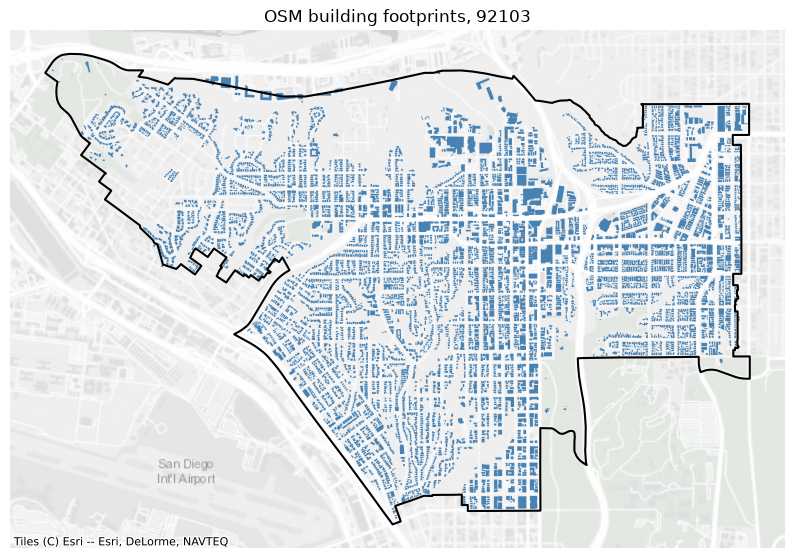

In [2]:
fig, ax = plt.subplots(figsize=(10, 10))
buildings.plot(ax=ax, color="steelblue")
boundary.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.5)
cx.add_basemap(ax, crs=buildings.crs, source=basemap)
ax.set_title("OSM building footprints, 92103")
ax.set_axis_off()

Zoomed in on University Ave & 5th Ave. This same window is reused in section 4.

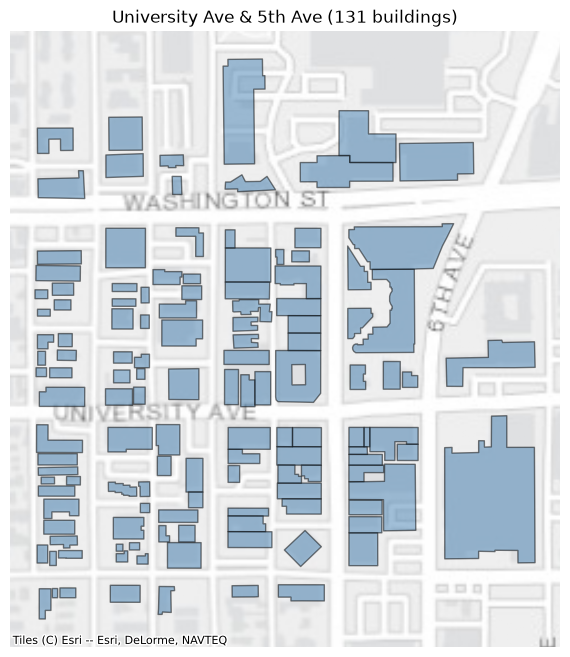

In [3]:
x, y, r = 484900, 3623430, 200  # center (m) and half-width (m)
zoom = buildings.cx[x - r:x + r, y - r:y + r]

fig, ax = plt.subplots(figsize=(8, 8))
zoom.plot(ax=ax, color="steelblue", edgecolor="black", alpha=0.5)
cx.add_basemap(ax, crs=buildings.crs, source=basemap, zoom=16)
ax.set_title(f"University Ave & 5th Ave ({len(zoom)} buildings)")
ax.set_axis_off()

**Observations**
- Most of the zip is well covered. The gaps are mostly canyons and the 163 freeway.
- Buildings line up with the streets on the basemap, so the coordinates look right.
- Some buildings stick out past the top edge of the zip since OSM includes anything touching the boundary.
- A lot of buildings share walls with their neighbors, which will matter later when we buffer them.

## 3. Footprint stats with DuckDB

In [4]:
import duckdb

con = duckdb.connect()
con.sql("INSTALL spatial; LOAD spatial")
con.sql("SET enable_progress_bar = false")
con.sql("""
    CREATE OR REPLACE TABLE buildings AS
    SELECT * FROM '../../data/raw/osm_buildings_92103.parquet'
""")

CountBIGINT
7966


### 3a. Number of buildings

In [5]:
con.sql("SELECT COUNT(*) AS n_buildings FROM buildings")

n_buildingsBIGINT
7966


### 3b. Vertices per building

`ST_NPoints` counts the closing point too, so a rectangle shows up as 5.

In [6]:
stats = con.sql("""
    SELECT id, building,
           ST_NPoints(geometry) AS n_vertices,
           ST_Area(geometry)    AS area_m2
    FROM buildings
""").df()

con.sql("""
    SELECT ST_NPoints(geometry) AS n_vertices, COUNT(*) AS n
    FROM buildings GROUP BY 1 ORDER BY n DESC LIMIT 8
""")

n_verticesUINTEGER,nBIGINT
5,4231
7,1220
9,802
11,420
13,301
15,167
17,140
19,72


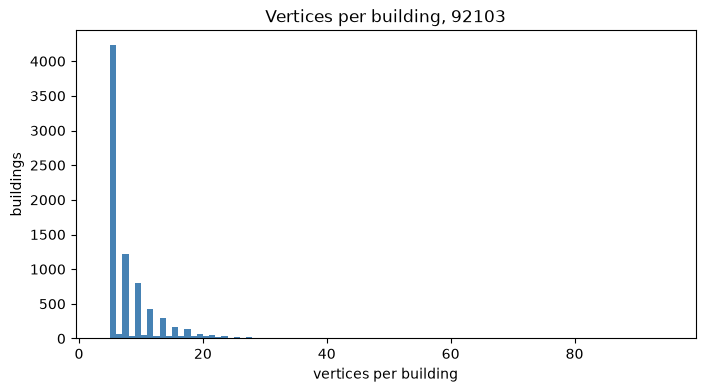

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(stats["n_vertices"], bins=range(4, stats["n_vertices"].max() + 2), color="steelblue")
ax.set_xlabel("vertices per building")
ax.set_ylabel("buildings")
ax.set_title("Vertices per building, 92103");

- Over half the buildings (4,231) have 5 points, so they're simple rectangles.
- The counts are almost always odd (7, 9, 11...), meaning an even number of corners. That fits boxy, right-angle buildings.
- Long tail up to 94 points. About 90 buildings have more than 30, usually big or oddly shaped ones that were traced in detail.

### 3c. Footprint area

In [8]:
con.sql("""
    SELECT MIN(ST_Area(geometry))    AS min_m2,
           MEDIAN(ST_Area(geometry)) AS median_m2,
           MAX(ST_Area(geometry))    AS max_m2,
           COUNT(*) FILTER (WHERE ST_Area(geometry) < 10) AS under_10m2
    FROM buildings
""")

min_m2DOUBLE,median_m2DOUBLE,max_m2DOUBLE,under_10m2BIGINT
2.5415952206473342,163.34847878887487,14295.069310167355,11


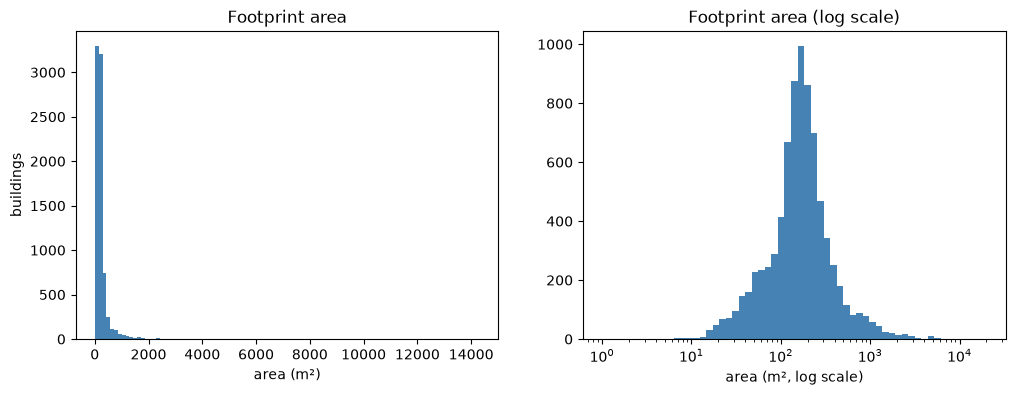

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(stats["area_m2"], bins=100, color="steelblue")
ax1.set_xlabel("area (m²)")
ax1.set_ylabel("buildings")
ax1.set_title("Footprint area")

ax2.hist(stats["area_m2"], bins=np.logspace(0, 4.3, 60), color="steelblue")
ax2.set_xscale("log")
ax2.set_xlabel("area (m², log scale)")
ax2.set_title("Footprint area (log scale)");

In [10]:
con.sql("""
    SELECT id, building, name, ROUND(ST_Area(geometry)) AS area_m2
    FROM buildings ORDER BY area_m2 DESC LIMIT 5
""")

idBIGINT,buildingVARCHAR,nameVARCHAR,area_m2DOUBLE
876026348,yes,NULL,14295.0
459309683,hospital,NULL,11797.0
17706457,residential,NULL,9207.0
531709017,industrial,AT&T Center,8254.0
1272369749,yes,First Avenue Parking Structure,6588.0


- Really skewed. Most buildings are small (median ~163 m²) but a few are huge, so the regular histogram is one tall bar. The log scale shows the shape better.
- The biggest ones are things like the hospital, the AT&T Center and a parking structure, which makes sense.
- 11 buildings are under 10 m² (smallest is 2.5 m²). Probably sheds or mapping mistakes, worth flagging later.

## 4. Manipulating footprints

All plots use the same zoom window as section 2.

In [11]:
def to_gdf(table):
    """Pull a DuckDB table into a GeoDataFrame for plotting."""
    df = con.sql(f"SELECT * EXCLUDE (geometry), ST_AsWKB(geometry) AS wkb FROM {table}").df()
    geom = gpd.GeoSeries.from_wkb(df.pop("wkb").apply(bytes), crs=buildings.crs)
    return gpd.GeoDataFrame(df, geometry=geom)

def plot_shift(original, shifted, title):
    fig, ax = plt.subplots(figsize=(8, 8))
    original.cx[x - r:x + r, y - r:y + r].plot(ax=ax, color="blue", alpha=0.5)
    shifted.cx[x - r:x + r, y - r:y + r].plot(ax=ax, color="red", alpha=0.5)
    cx.add_basemap(ax, crs=buildings.crs, source=basemap, zoom=16)
    ax.set_title(title)
    ax.set_axis_off()

### 4a. Shift all buildings 5 m east

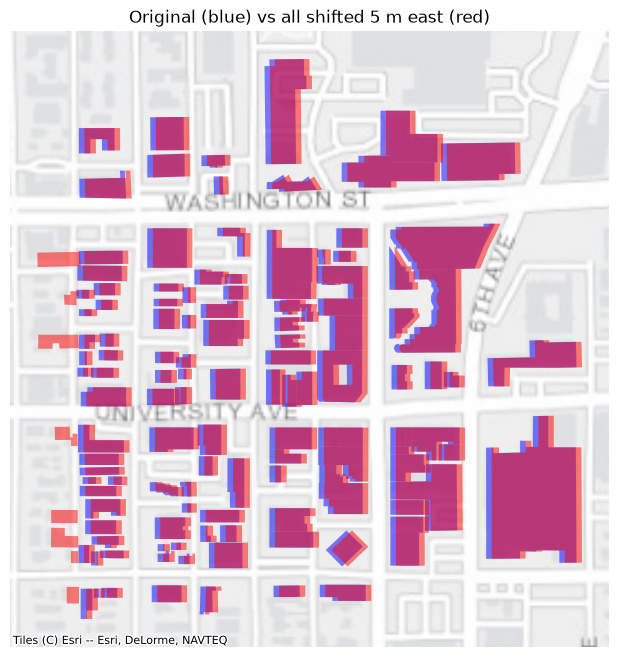

In [12]:
con.sql("""
    CREATE OR REPLACE TABLE shifted_all AS
    SELECT id, ST_Translate(geometry, 5, 0) AS geometry
    FROM buildings
""")

plot_shift(buildings, to_gdf("shifted_all"), "Original (blue) vs all shifted 5 m east (red)")

- Every building moves the same way, so the whole map just slides over. Purple is where old and new overlap, and each building gets a thin blue strip on the left and red strip on the right.
- On their own the shifted buildings still look normal. You'd only notice by comparing to the streets or the original.

### 4b. Shift a random 25% of buildings

In [13]:
# fixed seed so the same buildings get picked every run
con.sql("""
    CREATE OR REPLACE TABLE picked AS
    SELECT id FROM buildings USING SAMPLE 25 PERCENT (reservoir, 42)
""")

con.sql("""
    CREATE OR REPLACE TABLE shifted_25 AS
    SELECT b.id,
           p.id IS NOT NULL AS was_shifted,
           CASE WHEN p.id IS NOT NULL THEN ST_Translate(b.geometry, 5, 0)
                ELSE b.geometry END AS geometry
    FROM buildings b LEFT JOIN picked p USING (id)
""")

con.sql("SELECT was_shifted, COUNT(*) AS n FROM shifted_25 GROUP BY 1")

was_shiftedBOOLEAN,nBIGINT
False,5974
True,1992


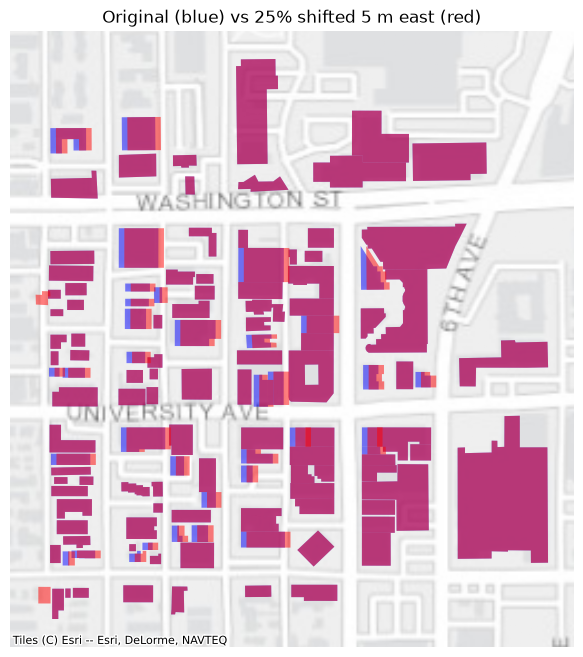

In [14]:
plot_shift(buildings, to_gdf("shifted_25"), "Original (blue) vs 25% shifted 5 m east (red)")

- Now it's mixed. Most buildings are still a single purple shape, but the shifted ones stick out and some run into their neighbors.
- Zoomed out it's really hard to see, since 5 m is small compared to the whole zip. These errors are easy to miss by eye.

**Can we detect it?**

Compare each building to its original (same `id`) and measure how far it moved and how much it overlaps (IoU).

In [15]:
con.sql("""
    SELECT s.was_shifted,
           COUNT(*) AS n,
           ROUND(AVG(ST_Distance(ST_Centroid(b.geometry), ST_Centroid(s.geometry))), 2) AS avg_moved_m,
           ROUND(AVG(ST_Area(ST_Intersection(b.geometry, s.geometry))
                     / ST_Area(ST_Union(b.geometry, s.geometry))), 3) AS avg_iou
    FROM buildings b JOIN shifted_25 s USING (id)
    GROUP BY 1 ORDER BY 1
""")

was_shiftedBOOLEAN,nBIGINT,avg_moved_mDOUBLE,avg_iouDOUBLE
False,5974,0.0,1.0
True,1992,5.0,0.395


- This catches every shifted building: they all moved exactly 5 m and IoU drops to about 0.4, while the rest stay at 0 m and IoU 1.
- The catch is it only works if you have a clean original to compare to, which usually isn't the case in real data.